# 01 · Análisis exploratorio — Producción no convencional
**Objetivo del proyecto:** predecir la producción mensual de **petróleo** y **gas** de pozos no convencionales de la **Cuenca Neuquina**.

Fuente: Secretaría de Energía de la Nación, *Producción de pozos de gas y petróleo no convencional* (Capítulo IV). Una fila = un pozo en un mes.
Unidades: petróleo en **m³**, gas en **miles de m³ (Mm³)**, `tef` = días efectivos de producción en el mes.

Usamos **Polars** (lectura mucho más rápida que pandas sobre 139 MB) y **DuckDB** para consultas SQL directas sobre los DataFrames.

**Contenido:** 1) estructura y calidad · 2) hallazgos de calidad en Neuquina · 3) distribuciones y outliers · 4) series temporales y formaciones · 5) GOR · 6) correlaciones · 7) historia de los pozos · conclusiones.

> **Qué hace esta celda:** importa las librerías, carga la configuración del proyecto (rutas y umbrales de `src/ypf_ds/config.py`) y define el estilo de los gráficos.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

> **Qué hace esta celda:** lee el CSV crudo completo (todas las cuencas y columnas) y muestra su tamaño y las primeras filas.

In [2]:
from ypf_ds.data.load import escanear_crudo, diagnostico
crudo = pl.read_csv(config.DATA_RAW, encoding="utf8-lossy", infer_schema_length=None)
print(crudo.shape)
crudo.head(3)

(421046, 40)


idempresa,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,iny_gas,iny_co2,iny_otro,tef,vida_util,tipoextraccion,tipoestado,tipopozo,observaciones,fechaingreso,rectificado,habilitado,idusuario,empresa,sigla,formprod,profundidad,formacion,idareapermisoconcesion,areapermisoconcesion,idareayacimiento,areayacimiento,cuenca,provincia,coordenadax,coordenaday,tipo_de_recurso,proyecto,clasificacion,subclasificacion,sub_tipo_recurso,fecha_data
str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,i64,str,str,str,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str
"""YSUR""",2015,1,132909,16.74,241.22,13.42,0.0,0.0,0.0,0.0,31.0,null,"""Plunger Lift""","""Extracción Efectiva""","""Gasífero""",null,"""2015-02-26 13:35:35.533458""","""f""","""t""",5,"""YSUR ENERGÍA ARGENTINA S.R.L.""","""AEA.NQ.RCo-1039""","""PREC""",2678.0,"""precuyo""","""SDD""","""AL SUR DE LA DORSAL""","""RQC""","""RANQUIL CO""","""NEUQUINA""","""Neuquén""",-69.202207,-39.08182,"""NO CONVENCIONAL""","""GAS PLUS""","""EXPLOTACION""","""DESARROLLO""","""TIGHT""","""2015-01-31"""
"""YSUR""",2018,1,132488,0.0,171.937,0.0,0.0,0.0,0.0,0.0,30.73,null,"""Surgencia Natural""","""Extracción Efectiva""","""Gasífero""",null,"""2018-02-10 08:37:14.717426""","""f""","""t""",444,"""YSUR ENERGÍA ARGENTINA S.R.L.""","""AEA.RN.EFO-99(d)""","""LAJA""",3828.0,"""lajas""","""FEO""","""ESTACION FERNANDEZ ORO""","""Z155""","""ESTACION FERNANDEZ ORO""","""NEUQUINA""","""Rio Negro""",-67.86496,-39.016722,"""NO CONVENCIONAL""","""GAS PLUS""","""EXPLOTACION""","""DESARROLLO""","""TIGHT""","""2018-01-31"""
"""YSUR""",2017,1,134325,22.34,365.61,1.2,0.0,0.0,0.0,0.0,31.0,null,"""Plunger Lift""","""Extracción Efectiva""","""Gasífero""",null,"""2017-02-16 13:45:37.233373""","""f""","""t""",444,"""YSUR ENERGÍA ARGENTINA S.R.L.""","""APA.RN.EFO-117(d)""","""LAJA""",3793.0,"""lajas""","""FEO""","""ESTACION FERNANDEZ ORO""","""Z155""","""ESTACION FERNANDEZ ORO""","""NEUQUINA""","""Rio Negro""",-67.849735,-39.020644,"""NO CONVENCIONAL""","""GAS PLUS""","""EXPLOTACION""","""DESARROLLO""","""TIGHT""","""2017-01-31"""


## 1. Estructura y calidad del dato crudo

> **Qué hace esta celda:** calcula el porcentaje de valores nulos por columna y lo grafica (solo las columnas que tienen nulos).

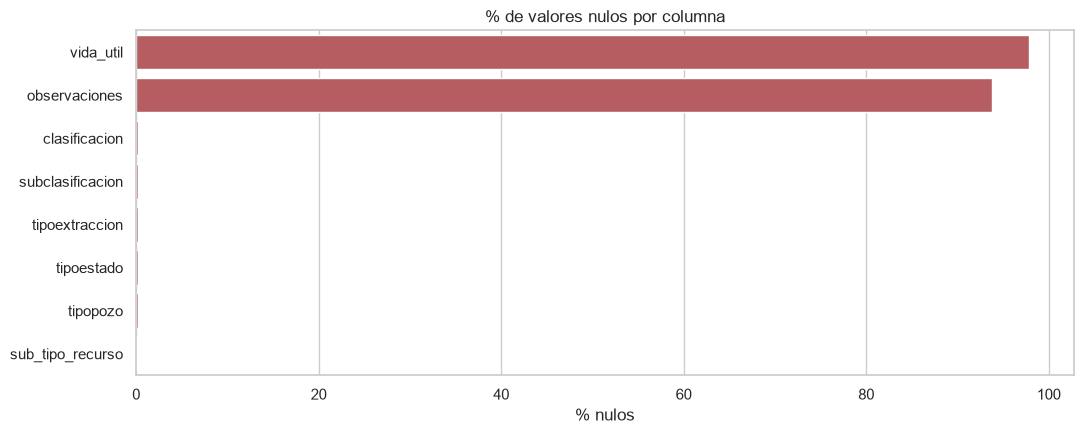

column,pct_nulos
str,f64
"""vida_util""",97.871016
"""observaciones""",93.734651
"""clasificacion""",0.218978
"""subclasificacion""",0.218978
"""tipoextraccion""",0.145827
"""tipoestado""",0.145827
"""tipopozo""",0.145827
"""sub_tipo_recurso""",0.107352


In [3]:
nulos = (crudo.null_count() / crudo.height * 100).transpose(include_header=True, column_names=["pct_nulos"])
nulos = nulos.filter(pl.col("pct_nulos") > 0).sort("pct_nulos", descending=True)
ax = sns.barplot(data=nulos.to_pandas(), y="column", x="pct_nulos", color="C3")
ax.set_title("% de valores nulos por columna"); ax.set_xlabel("% nulos"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_nulos.png", dpi=110); plt.show()
nulos

`vida_util` y `observaciones` están prácticamente vacías → se descartan. El resto tiene menos de 0,25 % de nulos.

> **Qué hace esta celda:** resume las variables numéricas principales con estadística descriptiva (media, desvío, mínimo, cuartiles y máximo).

In [4]:
crudo.select("prod_pet", "prod_gas", "prod_agua", "tef", "profundidad", "iny_agua", "iny_gas").describe()

statistic,prod_pet,prod_gas,prod_agua,tef,profundidad,iny_agua,iny_gas
str,f64,f64,f64,f64,f64,f64,f64
"""count""",421046.0,421046.0,421046.0,421046.0,421046.0,421046.0,421046.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",333.686552,629.669808,188.769196,21.964405,3765.601546,27.090517,35.33308
"""std""",937.959525,1628.853199,625.44647,12.181074,6536.666596,891.482388,8579.103467
"""min""",-0.001,-12.267,0.0,0.0,0.0,0.0,0.0
"""25%""",0.0,8.23,0.0,14.63,2858.0,0.0,0.0
"""50%""",7.782658,103.61,12.65,29.19,3272.0,0.0,0.0
"""75%""",122.2923,449.917,86.48,30.63,4700.0,0.0,0.0
"""max""",26593.261,40086.8,34792.95,79.34,378939.0,70278.85,3.569e6


Se ven valores imposibles (profundidad máxima de 378.939 m, `tef` mayor a 31 días, producciones negativas) y que las columnas de inyección son casi siempre 0.

> **Qué hace esta celda:** agrupa por cuenca con SQL (DuckDB): filas, pozos y producción total de petróleo y gas.

In [5]:
duckdb.sql("""
SELECT cuenca, COUNT(*) filas, COUNT(DISTINCT idpozo) pozos,
       ROUND(SUM(prod_pet)/1e6, 2) pet_Mm3, ROUND(SUM(prod_gas)/1e6, 2) gas_MMm3
FROM crudo GROUP BY cuenca ORDER BY filas DESC""").df()

,cuenca,filas,pozos,pet_Mm3,gas_MMm3
0,NEUQUINA,404037,4862,140.05,255.19
1,AUSTRAL,16197,209,0.31,9.58
2,GOLFO SAN JORGE,627,15,0.12,0.35
3,NOROESTE,185,3,0.02,0.00


La **Cuenca Neuquina** concentra el 96 % de las filas y casi todo el petróleo. Las otras cuencas tienen pocos pozos y otra geología: **filtramos solo Neuquina** para tener un modelo especializado.

> **Qué hace esta celda:** corre el diagnóstico de calidad del proyecto (`diagnostico()` de `load.py`) sobre Neuquina: nulos, duplicados, negativos, profundidades fuera de rango y coordenadas invertidas.

In [6]:
diag = diagnostico(escanear_crudo().filter(pl.col("cuenca") == "NEUQUINA"))
diag

{'filas': 404037,
 'pozos': 4862,
 'duplicados_pozo_mes': 0,
 'nulos_pct': {'tipoextraccion': 0.15,
  'tipoestado': 0.15,
  'tipopozo': 0.15,
  'sub_tipo_recurso': 0.03},
 'negativos': {'prod_pet': 0, 'prod_gas': 2, 'prod_agua': 0, 'tef': 0},
 'profundidad_fuera_rango': 6788,
 'coordenadas_invertidas': 68}

## 2. Hallazgos de calidad en Neuquina

> **Qué hace esta celda:** grafica la profundidad (recortada a 10.000 m), los días efectivos y las coordenadas crudas para ver anomalías.

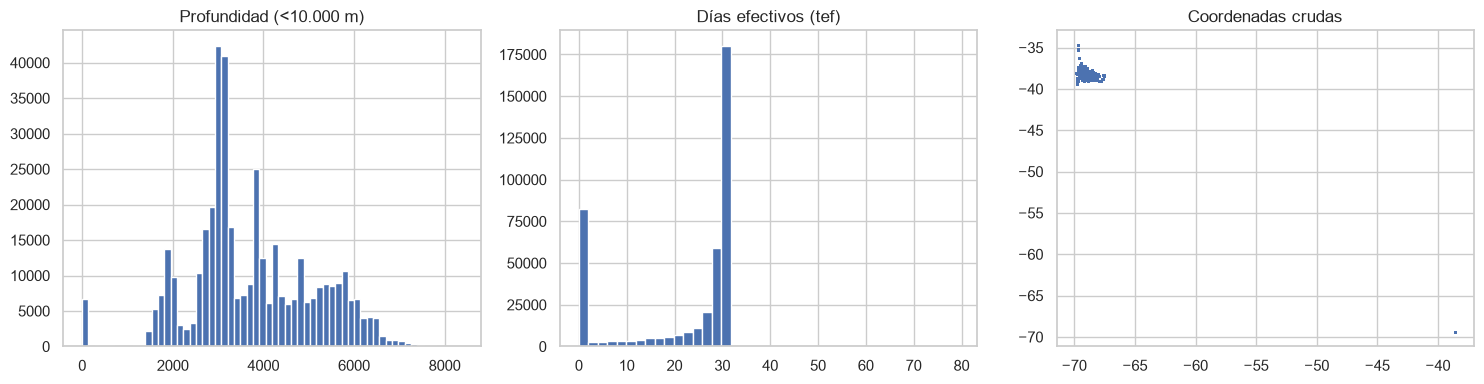

Profundidad máx: 378939.0 | ceros: 5738 | tef > 31: 15


In [7]:
neu = crudo.filter(pl.col("cuenca") == "NEUQUINA")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
prof = neu["profundidad"].to_numpy()
ax[0].hist(prof[prof < 10000], bins=60); ax[0].set_title("Profundidad (<10.000 m)")
ax[1].hist(neu["tef"].to_numpy(), bins=40); ax[1].set_title("Días efectivos (tef)")
ax[2].scatter(neu["coordenadax"], neu["coordenaday"], s=1, alpha=.3); ax[2].set_title("Coordenadas crudas")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_calidad.png", dpi=110); plt.show()
print("Profundidad máx:", prof.max(), "| ceros:", (prof == 0).sum(), "| tef > 31:", (neu["tef"] > 31).sum())

- **Profundidad:** un pozo con 378.939 m (error de carga) y ~1,4 % de filas en 0 → se tratan como faltantes.
- **tef:** algunos meses superan los días del mes, y hay meses con producción pero `tef = 0`.
- **Coordenadas:** un pozo tiene latitud y longitud invertidas (el punto aislado del scatter).

## 3. Distribuciones y outliers

> **Qué hace esta celda:** grafica la distribución de la producción mensual (solo meses con producción) en escala log10 y calcula percentiles.

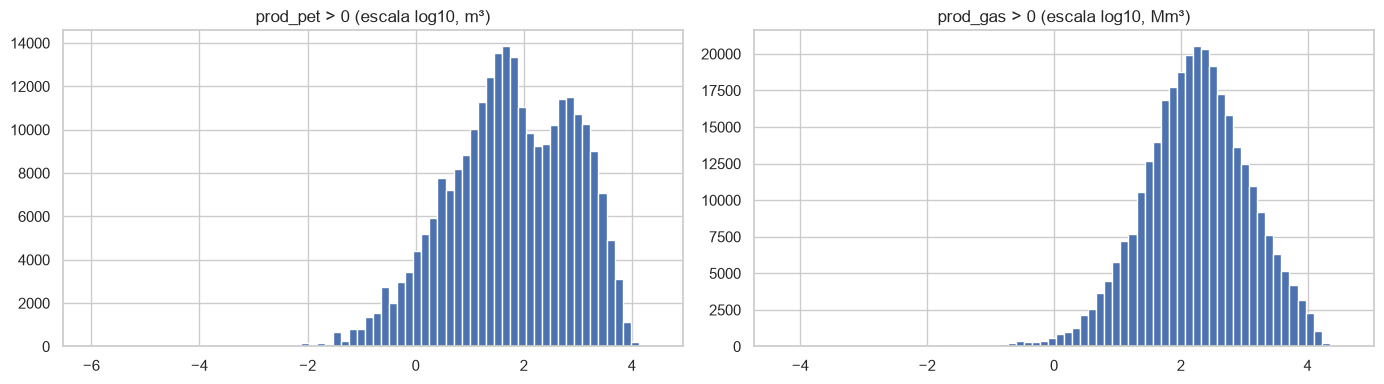

prod_pet_q50,prod_gas_q50,prod_pet_q90,prod_gas_q90,prod_pet_q99,prod_gas_q99
f64,f64,f64,f64,f64,f64
7.20497,95.65,1046.977,1561.181,4958.28,8922.283


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, u in [(ax[0], "prod_pet", "m³"), (ax[1], "prod_gas", "Mm³")]:
    v = neu[col].to_numpy(); v = v[v > 0]
    a.hist(np.log10(v), bins=70); a.set_title(f"{col} > 0 (escala log10, {u})")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_distribucion.png", dpi=110); plt.show()
neu.select(pl.col("prod_pet", "prod_gas").quantile(q).name.suffix(f"_q{int(q*100)}") for q in [.5, .9, .99])

Distribuciones **fuertemente sesgadas a la derecha** (el percentil 99 es cientos de veces la mediana) → se analizan en escala `log1p`.

> **Qué hace esta celda:** detecta outliers de profundidad con el criterio del rango intercuartílico (IQR): valores fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR], y lo muestra con un boxplot.

Q1=2955 m, Q3=4789 m, IQR=1834 → límites [204, 7540] m
Outliers IQR: 1324 filas (0.3%)


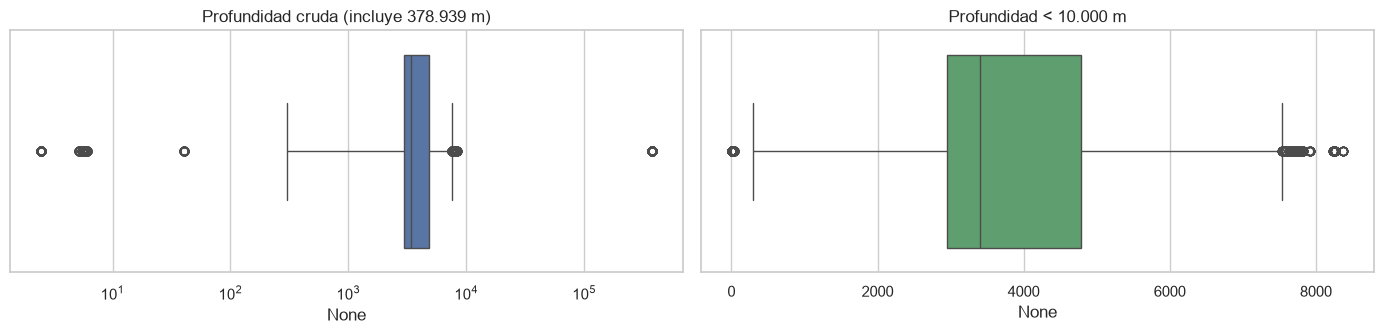

In [9]:
p = pd.Series(prof[prof > 0])
q1, q3 = p.quantile([.25, .75]); iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1={q1:.0f} m, Q3={q3:.0f} m, IQR={iqr:.0f} → límites [{lim_inf:.0f}, {lim_sup:.0f}] m")
print(f"Outliers IQR: {((p < lim_inf) | (p > lim_sup)).sum()} filas ({((p < lim_inf) | (p > lim_sup)).mean():.1%})")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
sns.boxplot(x=p, ax=ax[0]); ax[0].set_title("Profundidad cruda (incluye 378.939 m)"); ax[0].set_xscale("log")
sns.boxplot(x=p[p < 10000], ax=ax[1], color="C2"); ax[1].set_title("Profundidad < 10.000 m")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_outliers_profundidad.png", dpi=110); plt.show()

El IQR marca como outliers también a pozos profundos reales (horizontales de varios km): por eso **no se borran por IQR**, sino que se usa un rango físico plausible (300–8.000 m) y se imputan solo los valores imposibles.

> **Qué hace esta celda:** compara la producción por pozo-mes entre las formaciones principales con boxplots en escala logarítmica.

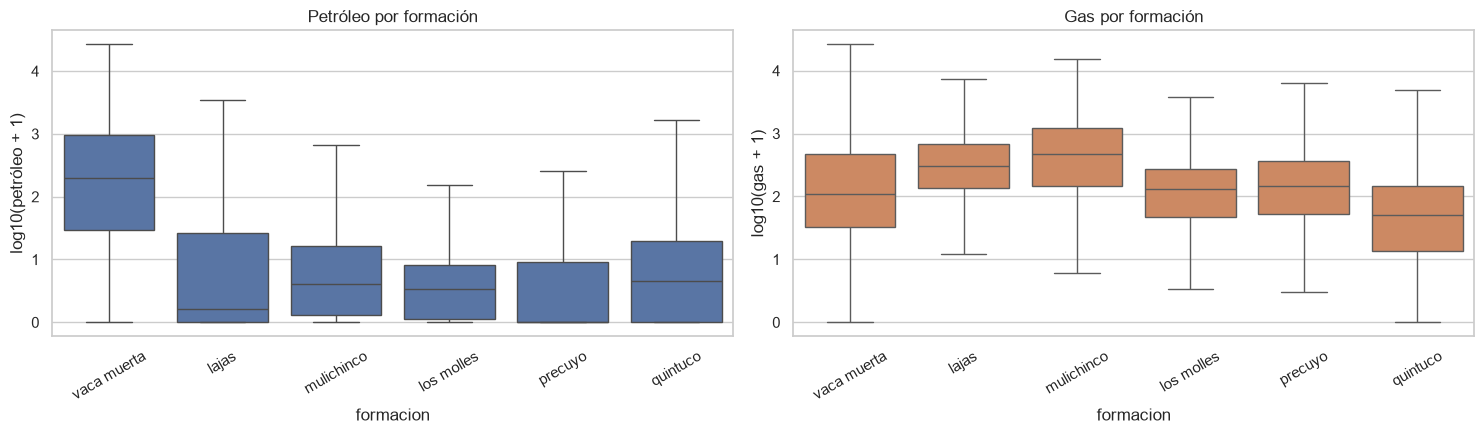

In [10]:
top_f = neu.group_by("formacion").len().sort("len", descending=True).head(6)["formacion"].to_list()
dfb = neu.filter(pl.col("formacion").is_in(top_f) & (pl.col("prod_pet") + pl.col("prod_gas") > 0)).to_pandas()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=dfb, x="formacion", y=np.log10(dfb.prod_pet + 1), ax=ax[0], showfliers=False, order=top_f); ax[0].set_ylabel("log10(petróleo + 1)")
sns.boxplot(data=dfb, x="formacion", y=np.log10(dfb.prod_gas + 1), ax=ax[1], showfliers=False, order=top_f, color="C1"); ax[1].set_ylabel("log10(gas + 1)")
for a, t in zip(ax, ["Petróleo por formación", "Gas por formación"]): a.set_title(t); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_boxplot_formacion.png", dpi=110); plt.show()

Vaca Muerta domina en petróleo; Lajas, Mulichinco y Los Molles son formaciones de **gas tight** con muy poco petróleo.

## 4. Series temporales, formaciones y operadoras

> **Qué hace esta celda:** calcula con SQL la producción total mensual y los pozos activos de Neuquina y los grafica en el tiempo.

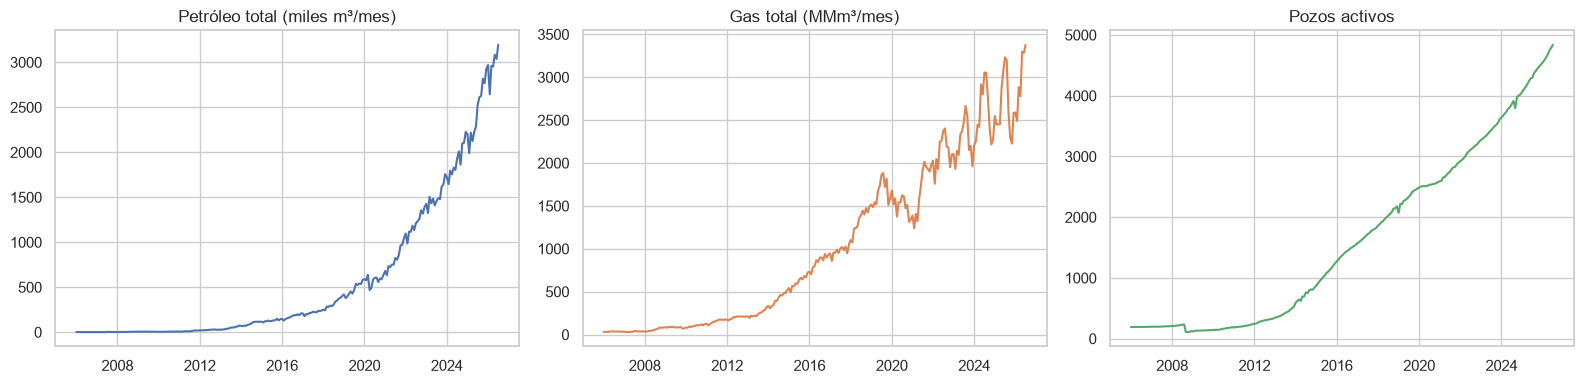

In [11]:
serie = duckdb.sql("""
SELECT make_date(anio, mes, 1) fecha, SUM(prod_pet) pet, SUM(prod_gas) gas, COUNT(DISTINCT idpozo) pozos
FROM neu GROUP BY 1 ORDER BY 1""").df()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(serie.fecha, serie.pet / 1e3); ax[0].set_title("Petróleo total (miles m³/mes)")
ax[1].plot(serie.fecha, serie.gas / 1e3, color="C1"); ax[1].set_title("Gas total (MMm³/mes)")
ax[2].plot(serie.fecha, serie.pozos, color="C2"); ax[2].set_title("Pozos activos")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_serie_temporal.png", dpi=110); plt.show()

El boom de Vaca Muerta es evidente desde 2014 en petróleo. El gas tight explica buena parte del gas temprano.

> **Qué hace esta celda:** arma un ranking de formaciones por pozos y producción acumulada.

In [12]:
formaciones = duckdb.sql("""
SELECT formacion, COUNT(DISTINCT idpozo) pozos, ROUND(SUM(prod_pet)/1e3) pet_miles_m3, ROUND(SUM(prod_gas)/1e3) gas_MMm3
FROM neu GROUP BY 1 ORDER BY pet_miles_m3 DESC LIMIT 10""").df()
formaciones

,formacion,pozos,pet_miles_m3,gas_MMm3
0,vaca muerta,3382,135488.0,159010.0
1,lajas,589,2578.0,37357.0
2,punta rosada,112,908.0,13477.0
3,mulichinco,259,414.0,24221.0
4,quintuco,86,186.0,994.0
5,los molles,216,174.0,5457.0
6,precuyo,81,150.0,4635.0
7,agrio,78,87.0,8787.0
8,lotena,10,21.0,533.0
9,basamento,16,19.0,426.0


> **Qué hace esta celda:** grafica la cantidad de pozos por operadora (top 10), por tipo de recurso (shale/tight) y por tipo de pozo.

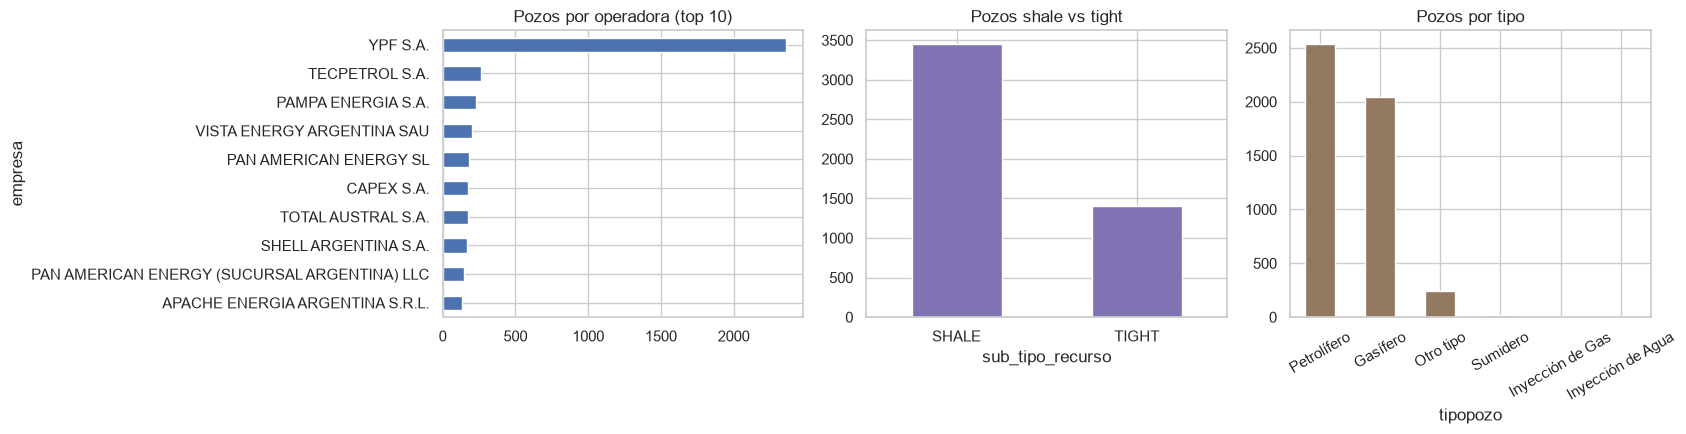

In [13]:
pz = neu.group_by("idpozo").agg(pl.col("empresa", "sub_tipo_recurso", "tipopozo").last()).to_pandas()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
pz.empresa.value_counts().head(10).sort_values().plot.barh(ax=ax[0], color="C0"); ax[0].set_title("Pozos por operadora (top 10)")
pz.sub_tipo_recurso.value_counts().plot.bar(ax=ax[1], color="C4", rot=0); ax[1].set_title("Pozos shale vs tight")
pz.tipopozo.value_counts().plot.bar(ax=ax[2], color="C5", rot=30); ax[2].set_title("Pozos por tipo")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_categoricas.png", dpi=110); plt.show()

YPF opera la mayoría de los pozos: es un **sesgo de representación** a tener en cuenta (el modelo va a ser más preciso para YPF que para operadoras chicas).

## 5. Petróleo vs gas por pozo: la relación gas/petróleo (GOR)

> **Qué hace esta celda:** calcula el GOR acumulado de cada pozo (m³ de gas por m³ de petróleo) y grafica su distribución en escala log, marcando el corte de 3.000 m³/m³.

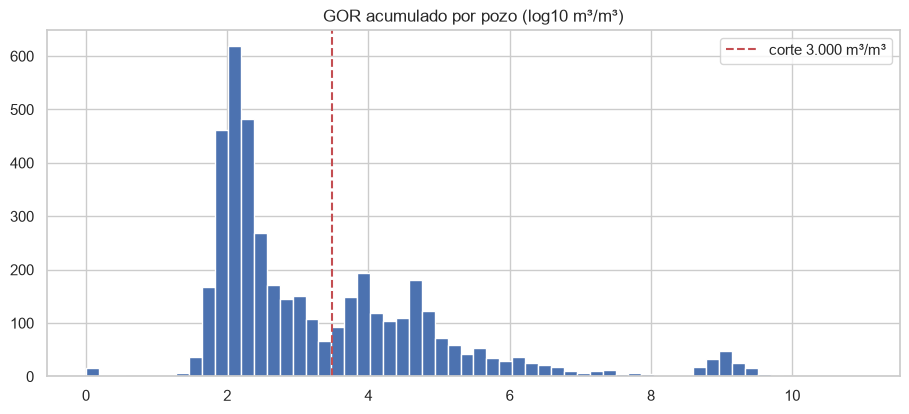

In [14]:
por_pozo = duckdb.sql("""
SELECT idpozo, SUM(prod_pet) pet, SUM(prod_gas) gas, ANY_VALUE(tipopozo) tipopozo
FROM neu GROUP BY 1 HAVING SUM(prod_pet) > 0""").df()
por_pozo["gor"] = por_pozo.gas * 1000 / por_pozo.pet
plt.hist(np.log10(por_pozo.gor.clip(1, None)), bins=60); plt.axvline(np.log10(3000), color="r", ls="--", label="corte 3.000 m³/m³")
plt.title("GOR acumulado por pozo (log10 m³/m³)"); plt.legend()
plt.savefig(config.DIR_FIGURAS / "01_gor.png", dpi=110); plt.show()

El GOR es **bimodal**: un grupo de pozos de petróleo (GOR de cientos) y otro de gas (decenas de miles). Esto justifica **modelar petróleo y gas por separado** y usar un corte de 3.000 m³/m³ para clasificar el fluido del pozo.

## 6. Matriz de correlación

> **Qué hace esta celda:** resume cada pozo (acumuladas, picos, profundidad, año de inicio, meses de historia, días efectivos) y calcula las matrices de correlación de **Pearson** (relación lineal, sobre log) y **Spearman** (relación monótona, robusta a outliers).

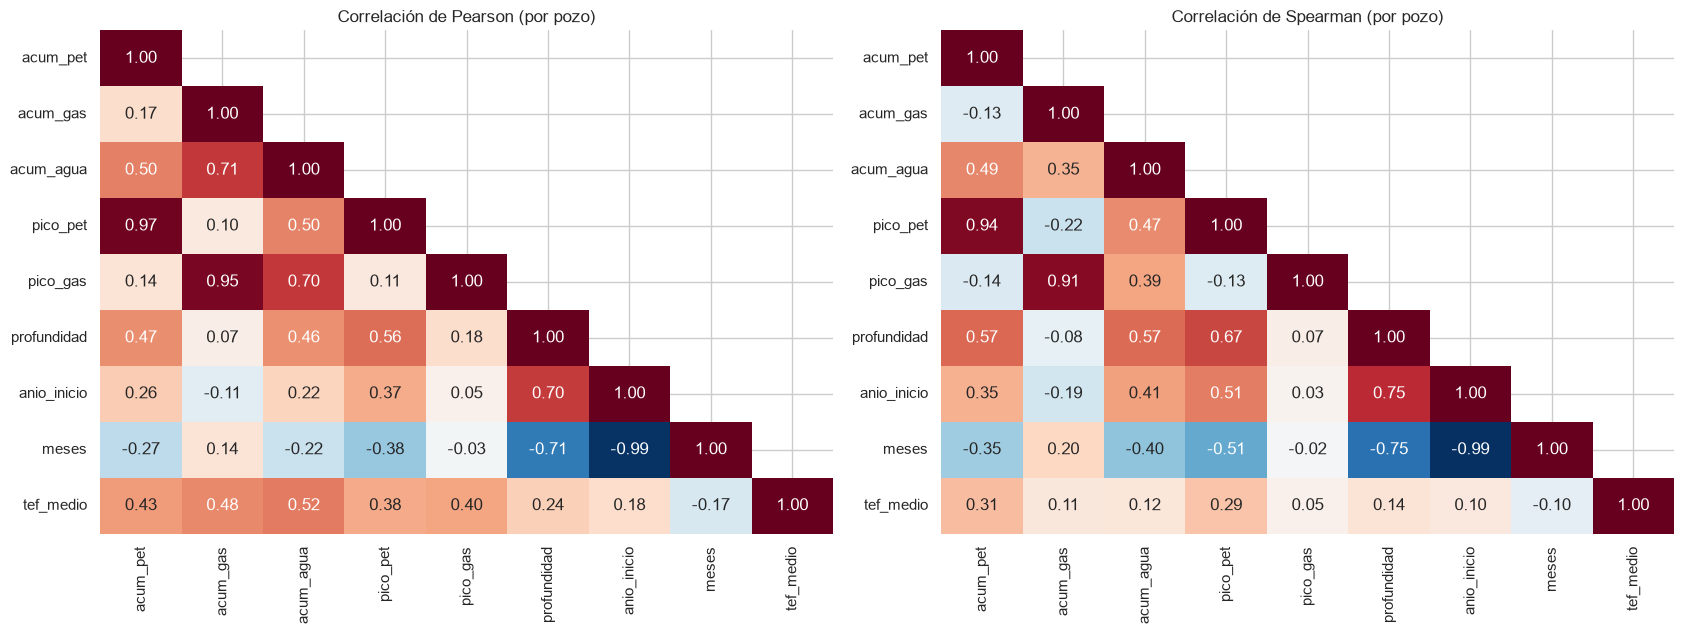

In [15]:
resumen = duckdb.sql("""
SELECT idpozo, SUM(prod_pet) acum_pet, SUM(prod_gas) acum_gas, SUM(prod_agua) acum_agua,
       MAX(prod_pet) pico_pet, MAX(prod_gas) pico_gas, MEDIAN(profundidad) profundidad,
       MIN(anio) anio_inicio, COUNT(*) meses, AVG(tef) tef_medio
FROM neu GROUP BY 1""").df().set_index("idpozo")
resumen = resumen[(resumen.profundidad > 300) & (resumen.profundidad < 8000)]
log_cols = ["acum_pet", "acum_gas", "acum_agua", "pico_pet", "pico_gas"]
res_log = resumen.copy(); res_log[log_cols] = np.log1p(res_log[log_cols])
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
for a, metodo, datos in [(ax[0], "pearson", res_log), (ax[1], "spearman", resumen)]:
    corr = datos.corr(method=metodo)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=a, mask=np.triu(np.ones_like(corr, bool), 1), cbar=False)
    a.set_title(f"Correlación de {metodo.capitalize()} (por pozo)")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_correlacion.png", dpi=110); plt.show()

Lectura de la matriz:
- **Profundidad ↔ pico y acumulada de petróleo**: correlación positiva moderada-fuerte (Spearman 0,57–0,67). Los pozos más profundos (profundidad medida) son los horizontales modernos con rama lateral larga.
- **Año de inicio ↔ profundidad** (0,70–0,75) y **año de inicio ↔ pico de petróleo** (0,37–0,51): los pozos recientes son más largos y producen más (mejor tecnología de completación).
- **Año de inicio ↔ meses**: negativa obvia (los pozos nuevos tienen menos historia).
- **Pico ↔ acumulada** del mismo fluido: muy alta. El pico inicial anticipa buena parte de la producción total.
- Petróleo y gas correlacionan poco entre sí a nivel pozo: confirma que son **dos poblaciones** y que conviene modelarlos por separado.

## 7. Historia de los pozos

> **Qué hace esta celda:** cuenta, por pozo, cuántos meses tiene y cuántos meses faltan entre su primer y su último registro (huecos por paradas), y grafica la distribución.

Pozos con meses faltantes: 703 de 4862


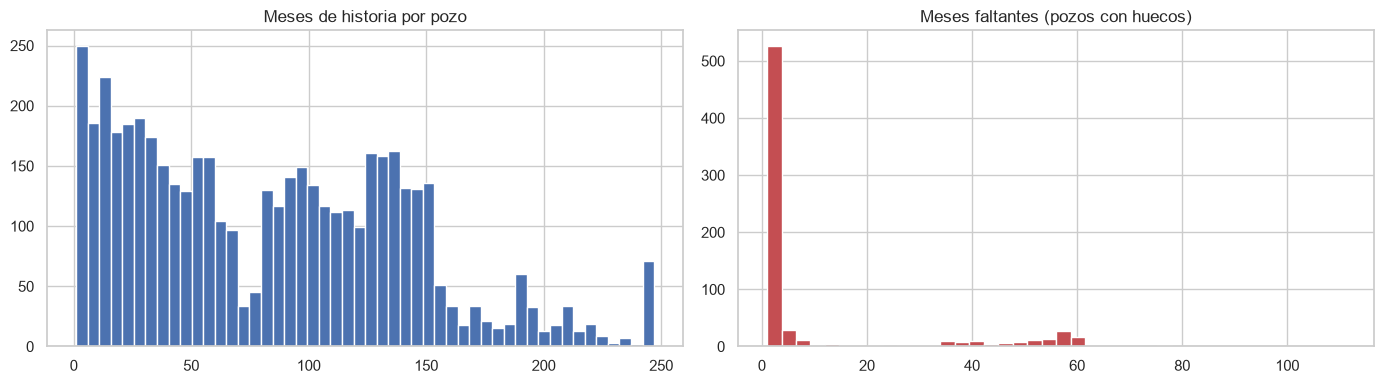

count    4862.000000
mean       83.100987
std        58.869762
min         1.000000
25%        31.000000
50%        82.000000
75%       128.000000
max       247.000000
Name: n, dtype: float64

In [16]:
meses = duckdb.sql("SELECT idpozo, COUNT(*) n, MIN(anio*12+mes) ini, MAX(anio*12+mes) fin FROM neu GROUP BY 1").df()
meses["huecos"] = (meses.fin - meses.ini + 1) - meses.n
print(f"Pozos con meses faltantes: {(meses.huecos > 0).sum()} de {len(meses)}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(meses.n, bins=50); ax[0].set_title("Meses de historia por pozo")
ax[1].hist(meses.huecos[meses.huecos > 0], bins=40, color="C3"); ax[1].set_title("Meses faltantes (pozos con huecos)")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_historia.png", dpi=110); plt.show()
meses.n.describe()

Hay pozos con **meses sin fila** (paradas). Por eso la limpieza arma una **grilla mensual continua por pozo**: así los *lags* (mes anterior, hace 3 meses…) son meses calendario reales y no filas.

## Conclusiones del EDA
1. **Alcance:** la Cuenca Neuquina concentra el 96 % de los datos → se trabaja solo con ella.
2. **Calidad:** hay errores de carga puntuales (profundidad de 378.939 m, coordenadas invertidas, `tef` mayor a los días del mes, negativos) y columnas vacías (`vida_util`, `observaciones`, `iny_*`).
3. **Outliers:** el criterio IQR marcaría como outliers a pozos profundos reales; se usa un **rango físico** y se imputa solo lo imposible.
4. **Distribución:** la producción está fuertemente sesgada → análisis en escala log y modelos de árboles (no dependen de la escala).
5. **Dos poblaciones:** el GOR bimodal y la baja correlación petróleo-gas por pozo justifican **modelos separados para petróleo y gas**.
6. **Variables prometedoras:** profundidad (proxy de rama lateral), año de inicio (tecnología) y pico inicial correlacionan fuerte con la producción.
7. **Sesgo:** YPF y Vaca Muerta dominan los datos; las predicciones para operadoras y formaciones chicas serán menos confiables.
8. **Estructura temporal:** hay meses faltantes → grilla mensual continua para calcular bien las variables temporales.

➡️ Estas decisiones se implementan en el notebook **02** (`src/ypf_ds/data/clean.py`).